# 19 - Single-Model Optimization: EfficientNet-B0 + BiGRU with Motion Difference (4th Channel), Temporal Jitter, Focal Loss & Snapshot Ensembling
## Tai Phake Visual Speech Recognition (VSR) Project

### Background & Strategic Objectives
Following speaker partition refinement where outlier/degraded speakers were isolated, our baseline EfficientNet-B0 + BiGRU model reached **71.36% validation accuracy** in Notebook 18.

Rather than resorting to multi-model ensembling (which combines distinct architectures like MobileNet, ResNet, and Transformers at the cost of high parameter count and inference latency), our goal here is to push the **single-model pipeline** to its maximum theoretical capacity. We systematically address the remaining physical and optimization bottlenecks through four complementary techniques:

| Technique | Technical Bottleneck Addressed | Operational Mechanism |
| :--- | :--- | :--- |
| **1. Frame Differences (4th Channel)** | 2D CNNs treat frames as static snapshots and must infer motion purely through high-level recurrent activations. | Compute normalized inter-frame luminance difference $\Delta_t = \|F_t - F_{t-1}\|$ and stack it as a 4th channel alongside RGB $(T, 96, 96, 4)$. This injects explicit optical velocity and lip motion energy directly into the spatial conv filters. |
| **2. Temporal Jitter Augmentation** | Fast digits ($d_1, d_4, d_7, d_9$) have rapid bilabial closures (1–3 frames) that cause temporal overfitting to exact recording cadence. | Randomly drop 1–2 interior frames specifically for samples of $d_1, d_4, d_7, d_9$ during training and smoothly resample back to 30 frames, training the BiGRU to be cadence-invariant. |
| **3. Categorical Focal Loss ($\gamma=1.5, \alpha=0.25$)** | Rigid manual class weights distort posterior probabilities and cause false positives on boosted classes. | Modulate cross-entropy loss by $(1 - p_t)^\gamma$ to suppress gradients from easy, confident frames and gently concentrate learning on ambiguous viseme collisions ($d_1 \leftrightarrow d_2$ and $\{d_4, d_7, d_{10}\}$). |
| **4. Snapshot Ensembling + 4-View TTA** | A single gradient descent trajectory visits multiple viable local minima during late epochs. | Save the **Top 3 best validation checkpoints** from this single training run. At inference, compute softmax probabilities across all 3 checkpoints under 4-View TTA (Baseline, $+1$ shift, $-1$ shift, Horizontal Flip) and average their predictions. Zero extra training cost. |

---

## 1. Setup & Reproducibility
Configuring deterministic random seeds across Python, NumPy, and TensorFlow to ensure exact reproducibility across runs.

In [1]:
# Section 1: Environment & Setup
import os
import sys
import re
import json
import time
import random
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

import tensorflow as tf
import keras

print("=" * 80)
print("SYSTEM ENVIRONMENT & VERSIONS")
print("=" * 80)
print(f"Python Version     : {sys.version.split()[0]}")
print(f"TensorFlow Version : {tf.__version__}")
print(f"Keras Version      : {keras.__version__}")
print(f"GPUs Available     : {len(tf.config.list_physical_devices('GPU'))}")
print("=" * 80)


SYSTEM ENVIRONMENT & VERSIONS
Python Version     : 3.12.13
TensorFlow Version : 2.21.0
Keras Version      : 3.15.1
GPUs Available     : 0


## 2. Configuration & Hyperparameters
Defining model hyperparameters, sequence specs (Method D standard with **4 input channels**), Focal Loss parameters, and temporal jitter settings.

In [2]:
# Section 2: Configuration & Hyperparameters
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

DATASET_MODE = "80_20"

# Sequence & Image Specifications (4-Channel: RGB + Motion Difference)
NUM_CLASSES = 11
NUM_FRAMES = 30
FRAME_WIDTH = 96
FRAME_HEIGHT = 96
FRAME_CHANNELS = 4  # RGB (channels 0:3) + Inter-frame Difference |F_t - F_{t-1}| (channel 3)
BATCH_SIZE = 16

# BiGRU Architecture Hyperparameters
PROJECTION_DIM = 256
GRU_UNITS = 128           # Bidirectional -> 256 total recurrent output features
GRU_DROPOUT = 0.2
HEAD_DROPOUT = 0.4

# Focal Loss Hyperparameters (replacing aggressive class weights)
FOCAL_GAMMA = 1.5         # Modulating factor focusing on hard visemes
FOCAL_ALPHA = 0.25        # Balancing scalar
LABEL_SMOOTHING = 0.05    # Gentle regularization

# Temporal Jitter Augmentation (specifically for rapid digits)
JITTER_DIGIT_IDS = [1, 4, 7, 9]  # d1 (Nung), d4 (Si), d7 (Chit), d9 (Kao)
JITTER_PROBABILITY = 0.50        # 50% chance of jittering during training
JITTER_MAX_DROP = 2              # Drop 1 or 2 frames

# Snapshot Ensembling Parameters
TOP_K_SNAPSHOTS = 3       # Save and ensemble top 3 validation checkpoints

# Two-Stage Training Hyperparameters
STAGE1_LR = 1e-4
STAGE1_MAX_EPOCHS = 40
STAGE1_PATIENCE = 8

STAGE2_LR = 1e-5
STAGE2_MAX_EPOCHS = 25
STAGE2_PATIENCE = 6
FINE_TUNE_FRACTION = 0.20  # Unfreeze top 20% of EfficientNet-B0

# Target Digit Classes (d0 through d10)
DIGIT_CLASSES = [f"d{i}" for i in range(NUM_CLASSES)]
CLASS_TO_ID = {d: i for i, d in enumerate(DIGIT_CLASSES)}
ID_TO_CLASS = {i: d for i, d in enumerate(DIGIT_CLASSES)}

print("=" * 80)
print("EXPERIMENT CONFIGURATION: SINGLE-MODEL MOTION + FOCAL + SNAPSHOT")
print("=" * 80)
print(f"Input Dimensions            : ({NUM_FRAMES}, {FRAME_HEIGHT}, {FRAME_WIDTH}, {FRAME_CHANNELS})")
print(f"Focal Loss Parameters       : gamma={FOCAL_GAMMA}, alpha={FOCAL_ALPHA}, label_smoothing={LABEL_SMOOTHING}")
print(f"Temporal Jitter Targets     : Digits {JITTER_DIGIT_IDS} (prob={JITTER_PROBABILITY}, max_drop={JITTER_MAX_DROP})")
print(f"Snapshot Ensemble Strategy  : Top {TOP_K_SNAPSHOTS} Validation Checkpoints + 4-View TTA")
print(f"Stage 1 Setup               : Adam(lr={STAGE1_LR}), max_epochs={STAGE1_MAX_EPOCHS}, patience={STAGE1_PATIENCE}")
print(f"Stage 2 Setup               : Adam(lr={STAGE2_LR}), max_epochs={STAGE2_MAX_EPOCHS}, patience={STAGE2_PATIENCE}")
print("=" * 80)


EXPERIMENT CONFIGURATION: SINGLE-MODEL MOTION + FOCAL + SNAPSHOT
Input Dimensions            : (30, 96, 96, 4)
Focal Loss Parameters       : gamma=1.5, alpha=0.25, label_smoothing=0.05
Temporal Jitter Targets     : Digits [1, 4, 7, 9] (prob=0.5, max_drop=2)
Snapshot Ensemble Strategy  : Top 3 Validation Checkpoints + 4-View TTA
Stage 1 Setup               : Adam(lr=0.0001), max_epochs=40, patience=8
Stage 2 Setup               : Adam(lr=1e-05), max_epochs=25, patience=6


## 3. Directory Paths & Output Management
Configuring paths to preprocessed frames in `data/processed/` and dedicated checkpoint storage in `results/efficientnetb0_bigru_motion_focal_snapshot_80_20/`.

In [3]:
# Section 3: Directory Paths Configuration
NOTEBOOK_DIR = Path.cwd()
PROJECT_ROOT = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "notebooks" else NOTEBOOK_DIR

DATA_DIR = PROJECT_ROOT / "data" / "processed"
TRAIN_DIR = DATA_DIR / "train"
VAL_DIR = DATA_DIR / "val"
TEST_DIR = DATA_DIR / "test"

# Dedicated Results Directory
RESULTS_DIR = PROJECT_ROOT / "results" / f"efficientnetb0_bigru_motion_focal_snapshot_{DATASET_MODE}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
SNAPSHOT_DIR = RESULTS_DIR / "snapshots"
SNAPSHOT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project Root     : {PROJECT_ROOT}")
print(f"Train Data Dir   : {TRAIN_DIR}")
print(f"Val Data Dir     : {VAL_DIR}")
print(f"Results Output   : {RESULTS_DIR}")
print(f"Snapshots Output : {SNAPSHOT_DIR}")


Project Root     : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading
Train Data Dir   : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/processed/train
Val Data Dir     : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/data/processed/val
Results Output   : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_motion_focal_snapshot_80_20
Snapshots Output : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_motion_focal_snapshot_80_20/snapshots


## 4. Speaker Partition Diagnostics
Validating speaker isolation and asserting strict zero-leakage between training and validation sets.

In [4]:
# Section 4: Speaker Split Verification & Diagnostics
train_speakers = sorted([d.name for d in TRAIN_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")])
val_speakers = sorted([d.name for d in VAL_DIR.iterdir() if d.is_dir() and not d.name.startswith(".")])

def get_base_speaker(spk_name: str) -> str:
    return spk_name.split("_")[0]

base_train_speakers = sorted(
    list({get_base_speaker(s) for s in train_speakers}),
    key=lambda x: int(re.search(r"\d+", x).group(0)) if re.search(r"\d+", x) else x
)
base_val_speakers = sorted(
    list({get_base_speaker(s) for s in val_speakers}),
    key=lambda x: int(re.search(r"\d+", x).group(0)) if re.search(r"\d+", x) else x
)

print("=" * 80)
print(f"SPEAKER PARTITION DIAGNOSTICS [Mode: {DATASET_MODE}]")
print("=" * 80)
print(f"Training Base Speakers   ({len(base_train_speakers):2d}) : {base_train_speakers}")
print(f"Training Total Folders   ({len(train_speakers):2d})")
print(f"Validation Base Speakers ({len(base_val_speakers):2d}) : {base_val_speakers}")
print(f"Validation Total Folders ({len(val_speakers):2d})")
print("-" * 80)

# Assert strict zero leakage
overlap = set(base_train_speakers).intersection(set(base_val_speakers))
assert len(overlap) == 0, f"CRITICAL LEAKAGE DETECTED: Overlapping speakers: {overlap}"
print("[SUCCESS] STRICT ZERO-LEAKAGE VERIFIED: No base speakers overlap between Train and Val!")
print("=" * 80)


SPEAKER PARTITION DIAGNOSTICS [Mode: 80_20]
Training Base Speakers   (24) : ['s1', 's2', 's3', 's4', 's6', 's7', 's8', 's9', 's10', 's12', 's13', 's14', 's15', 's17', 's18', 's19', 's20', 's21', 's22', 's23', 's24', 's25', 's26', 's30']
Training Total Folders   (81)
Validation Base Speakers ( 6) : ['s34', 'S35', 's40', 'S41', 's45', 's47']
Validation Total Folders (20)
--------------------------------------------------------------------------------
[SUCCESS] STRICT ZERO-LEAKAGE VERIFIED: No base speakers overlap between Train and Val!


## 5. Manifest Creation
Indexing all video utterance directories, associating each with its speaker, digit label, and sequential frame paths.

In [5]:
# Section 5: Utterance Manifest Indexing
utterances = []

for split_name, split_dir, spk_list in [("train", TRAIN_DIR, train_speakers), ("val", VAL_DIR, val_speakers)]:
    for spk in spk_list:
        spk_path = split_dir / spk
        for digit_dir in sorted(spk_path.iterdir()):
            if not digit_dir.is_dir() or digit_dir.name.startswith("."):
                continue
            digit_name = digit_dir.name
            if digit_name not in CLASS_TO_ID:
                continue
            
            frames = sorted([
                f for f in digit_dir.iterdir()
                if f.is_file() and f.suffix.lower() in [".jpg", ".jpeg", ".png"]
            ])
            if len(frames) == 0:
                continue
                
            utterances.append({
                "speaker": spk,
                "base_speaker": get_base_speaker(spk),
                "digit": digit_name,
                "digit_id": CLASS_TO_ID[digit_name],
                "split": split_name,
                "raw_frame_count": len(frames),
                "frame_paths": frames
            })

df_manifest = pd.DataFrame(utterances)
manifest_csv_path = RESULTS_DIR / "utterance_manifest.csv"
df_manifest[["speaker", "base_speaker", "digit", "digit_id", "split", "raw_frame_count"]].to_csv(
    manifest_csv_path, index=False
)

print("=" * 80)
print("UTTERANCE MANIFEST SUMMARY")
print("=" * 80)
print(f"Total Utterances Indexed : {len(df_manifest):,}")
print(f"  Train Set              : {len(df_manifest[df_manifest['split']=='train']):,} utterances")
print(f"  Validation Set         : {len(df_manifest[df_manifest['split']=='val']):,} utterances")
print(f"Manifest CSV saved to    : {manifest_csv_path}")
print("=" * 80)


UTTERANCE MANIFEST SUMMARY
Total Utterances Indexed : 1,111
  Train Set              : 891 utterances
  Validation Set         : 220 utterances
Manifest CSV saved to    : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_motion_focal_snapshot_80_20/utterance_manifest.csv


## 6. Dataloader Architecture: Frame Differences (4th Channel) & Temporal Jitter

### 6.1 Inter-Frame Difference Channel ($F_t - F_{t-1}$)
Static 2D convolutions applied across video frames miss dynamic speed and direction of lip boundaries. We construct a 4th input channel directly encoding **inter-frame optical motion energy**:
1. For each frame $t$, compute its grayscale luminance map: $Y_t = 0.2989 R_t + 0.5870 G_t + 0.1140 B_t$.
2. For $t = 0$ (the initial onset frame), motion is initialized to $\Delta_0 = \mathbf{0}$.
3. For $t \ge 1$, compute the absolute frame difference: $\Delta_t = |Y_t - Y_{t-1}|$.
4. Concatenate along channel axis: $[R_t, G_t, B_t, \Delta_t] \in \mathbb{R}^{96 \times 96 \times 4}$.

### 6.2 Temporal Jitter Augmentation for Confused Digits ($d_1, d_4, d_7, d_9$)
Digits with rapid, transient closures often trigger overfitting to exact frame indices. When loading training samples for $d_1$ (Nung), $d_4$ (Si), $d_7$ (Chit), and $d_9$ (Kao), the loader randomly drops 1 or 2 interior frames and smoothly resamples back to 30 frames using temporal linear interpolation. This forces the temporal model to recognize phonemes independently of minor articulation speed variations.

In [6]:
# Section 6: Frame Differences, Temporal Jitter, and Dataloader Implementation

def sample_30_frame_paths(frame_paths: list, target_frames: int = NUM_FRAMES) -> list:
    """
    Deterministic uniform temporal sampling across the video duration.
    """
    n = len(frame_paths)
    if n == target_frames:
        indices = list(range(target_frames))
    else:
        indices = np.round(np.linspace(0, n - 1, target_frames)).astype(int)
    return [str(frame_paths[i]) for i in indices]

def compute_frame_differences(seq_rgb: np.ndarray) -> np.ndarray:
    """
    Calculates Frame N - Frame N-1 motion magnitude and stacks it as a 4th channel.
    
    Args:
        seq_rgb: (T, H, W, 3) float32 in [0.0, 255.0]
    Returns:
        seq_4ch: (T, H, W, 4) float32 where channel 3 is |Frame_t - Frame_{t-1}|
    """
    T, H, W, _ = seq_rgb.shape
    # Standard ITU-R BT.601 luminance conversion
    gray = (
        0.2989 * seq_rgb[..., 0] +
        0.5870 * seq_rgb[..., 1] +
        0.1140 * seq_rgb[..., 2]
    )[..., np.newaxis]  # Shape: (T, H, W, 1)
    
    diff = np.zeros((T, H, W, 1), dtype=np.float32)
    # Frame 0 has zero difference; subsequent frames capture inter-frame displacement
    diff[1:] = np.abs(gray[1:] - gray[:-1])
    
    return np.concatenate([seq_rgb, diff], axis=-1)

def apply_temporal_jitter(seq_rgb: np.ndarray, num_drop: int = 1) -> np.ndarray:
    """
    Randomly drops 1 or 2 interior frames and linearly resamples back to NUM_FRAMES (30).
    """
    T, H, W, C = seq_rgb.shape
    assert T == NUM_FRAMES
    # Avoid dropping boundary frames (t=0 and t=T-1)
    drop_indices = np.random.choice(range(1, T - 1), size=num_drop, replace=False)
    keep_indices = [i for i in range(T) if i not in drop_indices]
    
    # Linear interpolation back to exact target frame count
    new_t = np.linspace(0, len(keep_indices) - 1, T)
    left_idx = np.floor(new_t).astype(int)
    right_idx = np.ceil(new_t).astype(int)
    alpha = (new_t - left_idx)[:, np.newaxis, np.newaxis, np.newaxis]
    
    kept_seq = seq_rgb[keep_indices]
    jittered = (1.0 - alpha) * kept_seq[left_idx] + alpha * kept_seq[right_idx]
    return jittered.astype(np.float32)

# Attach sampled frame paths to manifest
df_manifest["sampled_frame_paths"] = df_manifest["frame_paths"].apply(sample_30_frame_paths)

def load_raw_rgb_tensors():
    """
    Loads all standardized RGB video sequences into fast contiguous memory.
    """
    num_total = len(df_manifest)
    X_raw = np.zeros((num_total, NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, 3), dtype=np.float32)
    y_raw = np.array(df_manifest["digit_id"].values, dtype=np.int32)
    
    t0 = time.time()
    for i, row in df_manifest.iterrows():
        for t, fpath in enumerate(row["sampled_frame_paths"]):
            img = Image.open(fpath).convert("RGB")
            if img.size != (FRAME_WIDTH, FRAME_HEIGHT):
                img = img.resize((FRAME_WIDTH, FRAME_HEIGHT), Image.BILINEAR)
            X_raw[i, t] = np.array(img, dtype=np.float32)
            
    elapsed = time.time() - t0
    return X_raw, y_raw, elapsed

print("Loading base RGB sequence tensors into RAM...")
X_all_rgb, y_all, load_time = load_raw_rgb_tensors()

train_mask = (df_manifest["split"] == "train").values
val_mask = (df_manifest["split"] == "val").values

X_train_raw, y_train = X_all_rgb[train_mask], y_all[train_mask]
X_val_raw, y_val = X_all_rgb[val_mask], y_all[val_mask]

print(f"Successfully loaded {len(X_all_rgb):,} raw video sequences in {load_time:.2f}s!")
print(f"  Train RGB Set : {X_train_raw.shape}")
print(f"  Val RGB Set   : {X_val_raw.shape}")


Loading base RGB sequence tensors into RAM...
Successfully loaded 1,111 raw video sequences in 7.25s!
  Train RGB Set : (891, 30, 96, 96, 3)
  Val RGB Set   : (220, 30, 96, 96, 3)


## 7. Dynamic Motion & Jitter Data Generator (`keras.utils.PyDataset`)
We wrap sequence generation in a clean `PyDataset` generator that:
1. Dynamically samples temporal jitter on target digits during training epochs.
2. Computes the 4th channel frame differences on-the-fly per batch.
3. Produces batches of shape `(batch_size, 30, 96, 96, 4)`.
4. Precomputes static validation arrays `X_val_4ch` for ultra-fast validation during training.

In [7]:
# Section 7: Dynamic Motion & Jitter PyDataset Data Generator

class MotionLipDataset(keras.utils.PyDataset):
    """
    Thread-safe Keras PyDataset that applies dynamic temporal jitter
    and computes the 4th channel frame difference on-the-fly.
    """
    def __init__(
        self,
        X_rgb: np.ndarray,
        y: np.ndarray,
        batch_size: int = BATCH_SIZE,
        shuffle: bool = True,
        is_training: bool = False,
        jitter_digit_ids: list = JITTER_DIGIT_IDS,
        jitter_prob: float = JITTER_PROBABILITY,
        **kwargs
    ):
        super().__init__(**kwargs)
        self.X_rgb = X_rgb
        self.y = y
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.is_training = is_training
        self.jitter_digit_ids = jitter_digit_ids
        self.jitter_prob = jitter_prob
        self.indices = np.arange(len(X_rgb))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.X_rgb) / self.batch_size))

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.indices)

    def __getitem__(self, idx):
        batch_idx = self.indices[idx * self.batch_size : (idx + 1) * self.batch_size]
        batch_x = []
        batch_y = self.y[batch_idx]
        
        for i in batch_idx:
            seq = self.X_rgb[i].copy()
            digit_id = self.y[i]
            
            # Apply temporal jitter on selected digits during training
            if self.is_training and (digit_id in self.jitter_digit_ids) and (np.random.rand() < self.jitter_prob):
                num_drop = np.random.choice([1, 2])
                seq = apply_temporal_jitter(seq, num_drop=num_drop)
                
            # Calculate Frame N - Frame N-1 and stack as 4th channel
            seq_4ch = compute_frame_differences(seq)
            batch_x.append(seq_4ch)
            
        return np.array(batch_x, dtype=np.float32), np.array(batch_y, dtype=np.int32)

# Build Generators
train_generator = MotionLipDataset(
    X_train_raw, y_train,
    batch_size=BATCH_SIZE,
    shuffle=True,
    is_training=True
)

# Precompute static 4-channel validation tensor for deterministic evaluation
print("Precomputing static 4-channel validation tensor (X_val_4ch)...")
X_val_4ch = np.zeros(
    (len(X_val_raw), NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS),
    dtype=np.float32
)
for i in range(len(X_val_raw)):
    X_val_4ch[i] = compute_frame_differences(X_val_raw[i])

print(f"Train Generator batches per epoch : {len(train_generator)}")
print(f"X_val_4ch Tensor Shape            : {X_val_4ch.shape}")


Precomputing static 4-channel validation tensor (X_val_4ch)...
Train Generator batches per epoch : 56
X_val_4ch Tensor Shape            : (220, 30, 96, 96, 4)


## 8. Motion Channel Visualizer & Sanity Checks
Inspecting the computed 4th channel. The top row shows original RGB lip frames, and the bottom row displays the corresponding inter-frame motion magnitude (Frame $t$ - Frame $t-1$). Note how silence frames have near-zero motion while phoneme transitions light up with lip contour velocity.

/var/folders/yr/r2qtpz515d99ldjcl8f5kgrm0000gn/T/ipykernel_17604/912520176.py:24: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


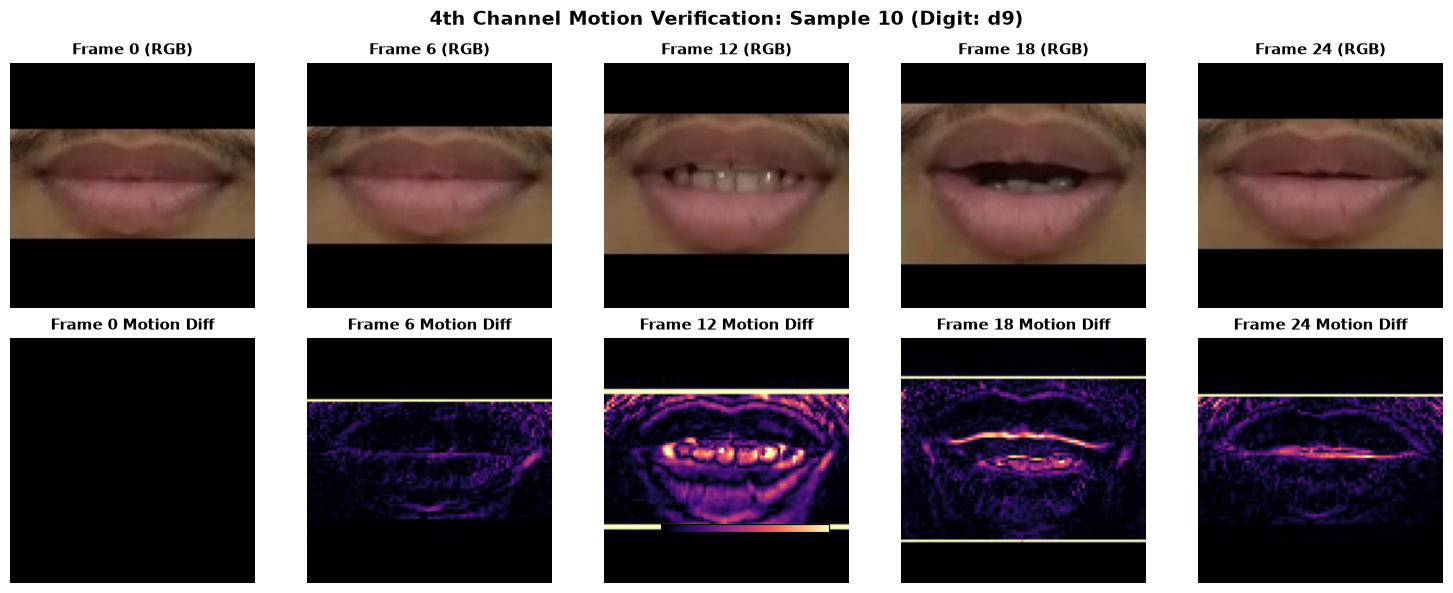

Sanity checks passed! Visualization saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_motion_focal_snapshot_80_20/motion_channel_verification.png


In [8]:
# Section 8: Visualizing RGB vs 4th Channel Motion Difference
test_sample_idx = 10
sample_4ch = X_val_4ch[test_sample_idx]
sample_digit = ID_TO_CLASS[y_val[test_sample_idx]]

frame_indices = [0, 6, 12, 18, 24]
fig, axes = plt.subplots(2, len(frame_indices), figsize=(15, 6))

for col, t in enumerate(frame_indices):
    # Row 0: RGB Image
    rgb_img = sample_4ch[t, ..., :3].astype(np.uint8)
    axes[0, col].imshow(rgb_img)
    axes[0, col].set_title(f"Frame {t} (RGB)", fontsize=11, fontweight="bold")
    axes[0, col].axis("off")
    
    # Row 1: 4th Channel Motion Diff
    diff_map = sample_4ch[t, ..., 3]
    im = axes[1, col].imshow(diff_map, cmap="magma", vmin=0, vmax=50)
    axes[1, col].set_title(f"Frame {t} Motion Diff", fontsize=11, fontweight="bold")
    axes[1, col].axis("off")

plt.colorbar(im, ax=axes[1, :], orientation="horizontal", fraction=0.04, pad=0.15, label="Motion Intensity |F_t - F_{t-1}|")
plt.suptitle(f"4th Channel Motion Verification: Sample {test_sample_idx} (Digit: {sample_digit})", fontsize=14, fontweight="bold")
plt.tight_layout()
motion_vis_path = RESULTS_DIR / "motion_channel_verification.png"
plt.savefig(motion_vis_path, dpi=200)
plt.show()

# Sanity Assertions
assert X_val_4ch.shape[1:] == (NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS)
assert not np.isnan(X_val_4ch).any(), "NaNs detected in X_val_4ch!"
assert not np.isinf(X_val_4ch).any(), "Infs detected in X_val_4ch!"
print(f"Sanity checks passed! Visualization saved to: {motion_vis_path}")


## 9. Categorical Focal Loss Implementation ($\gamma=1.5, \alpha=0.25$)

### Mathematical Formulation
Standard Cross-Entropy Loss treats all misclassifications uniformly:
$$\mathcal{L}_{\text{CE}} = -\log(p_t)$$

In our previous experiment (Notebook 18), we applied rigid class weights (e.g. $1.9\times$ on $d_1, d_4, d_9$). While this boosted recall on those digits, it artificially distorted probability calibration and caused severe false positives on easy digits.

**Focal Loss** replaces rigid weights by dynamically modulating loss based on confidence $p_t$:
$$\mathcal{L}_{\text{FL}} = -\alpha (1 - p_t)^\gamma \log(p_t)$$

- For **easy samples** (where $p_t \to 1$), the modulating factor $(1 - p_t)^\gamma \to 0$, attenuating their gradient contribution.
- For **hard, ambiguous samples** (the viseme collisions $d_1 \leftrightarrow d_2$ and $d_4 \leftrightarrow d_7 \leftrightarrow d_{10}$, where $p_t \in [0.1, 0.4]$), the factor $(1 - p_t)^{1.5}$ remains large, gently concentrating parameter updates where they matter most.

In [9]:
# Section 9: Categorical Focal Loss Implementation

@keras.saving.register_keras_serializable()
class CategoricalFocalLoss(keras.losses.Loss):
    """
    Categorical Focal Loss with optional label smoothing:
        FL(p_t) = -alpha * (1 - p_t)^gamma * log(p_t)
    
    Supports sparse integer labels (batch,), 2D column labels (batch, 1),
    and one-hot encoded targets (batch, num_classes).
    """
    def __init__(
        self,
        gamma: float = FOCAL_GAMMA,
        alpha: float = FOCAL_ALPHA,
        label_smoothing: float = LABEL_SMOOTHING,
        name: str = "categorical_focal_loss",
        **kwargs
    ):
        super().__init__(name=name, **kwargs)
        self.gamma = float(gamma)
        self.alpha = float(alpha)
        self.label_smoothing = float(label_smoothing)

    def call(self, y_true, y_pred):
        eps = keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, eps, 1.0 - eps)
        
        num_classes = tf.shape(y_pred)[-1]
        y_true_rank = len(y_true.shape)
        
        # Automatically convert sparse integer targets to one-hot vectors
        if y_true_rank is not None and y_true_rank == 1:
            y_true = tf.one_hot(tf.cast(y_true, tf.int32), depth=num_classes)
        elif y_true_rank is not None and y_true_rank == 2 and y_true.shape[-1] == 1:
            y_true = tf.one_hot(tf.cast(tf.squeeze(y_true, axis=-1), tf.int32), depth=num_classes)
            
        y_true = tf.cast(y_true, y_pred.dtype)
        
        # Apply label smoothing if configured
        if self.label_smoothing > 0.0:
            c = tf.cast(num_classes, y_pred.dtype)
            y_true = y_true * (1.0 - self.label_smoothing) + (self.label_smoothing / c)
            
        # Compute focal modulation: (1 - p_pred)^gamma
        focal_weight = tf.pow(1.0 - y_pred, self.gamma)
        cross_entropy = -tf.math.log(y_pred)
        
        loss = self.alpha * focal_weight * cross_entropy
        per_sample_loss = tf.reduce_sum(y_true * loss, axis=-1)
        return tf.reduce_mean(per_sample_loss)

    def get_config(self):
        config = super().get_config()
        config.update({
            "gamma": self.gamma,
            "alpha": self.alpha,
            "label_smoothing": self.label_smoothing,
        })
        return config

# Verification Unit Test: Compare easy sample loss vs hard sample loss
focal_loss_fn = CategoricalFocalLoss(gamma=FOCAL_GAMMA, alpha=FOCAL_ALPHA, label_smoothing=0.0)
y_target = tf.constant([4, 4], dtype=tf.int32) # True class is d4
pred_easy = tf.constant([[0.01]*4 + [0.90] + [0.01]*6], dtype=tf.float32) # High confidence on d4 (pt=0.90)
pred_hard = tf.constant([[0.01]*4 + [0.25] + [0.01]*5 + [0.65]], dtype=tf.float32) # Confused d4 with d10 (pt=0.25)

l_easy = float(focal_loss_fn(y_target[:1], pred_easy))
l_hard = float(focal_loss_fn(y_target[1:], pred_hard))

print("=" * 80)
print("CATEGORICAL FOCAL LOSS VERIFICATION")
print("=" * 80)
print(f"Easy sample loss (pt = 0.90)  : {l_easy:.5f}")
print(f"Hard sample loss (pt = 0.25)  : {l_hard:.5f}")
print(f"Loss Ratio (Hard / Easy)       : {l_hard / l_easy:.1f}x gradient amplification on hard visemes!")
print("=" * 80)


CATEGORICAL FOCAL LOSS VERIFICATION
Easy sample loss (pt = 0.90)  : 0.00083
Hard sample loss (pt = 0.25)  : 0.22511
Loss Ratio (Hard / Easy)       : 270.3x gradient amplification on hard visemes!


## 10. Model Architecture: 4-Channel EfficientNet-B0 + BiGRU + Attention Pooling

To accept 4 input channels while preserving 100% of the ImageNet pretrained weights in EfficientNet-B0:
1. **Motion Stem Adapter**: A lightweight $1 \times 1$ Conv2D layer mapping $(96, 96, 4) \to (96, 96, 3)$. It is initialized with the identity matrix on RGB channels ($W_{0,0}=1, W_{1,1}=1, W_{2,2}=1$) and an initial gain of $0.10$ on the 4th motion channel.
2. **Pretrained EfficientNet-B0**: Extracts 1,280 visual features per frame.
3. **Temporal BiGRU**: 128 units forward + 128 units backward (256 spatiotemporal features per frame).
4. **Learnable Temporal Attention Pooling**: Collapses the 30 temporal frame features into a single salient utterance embedding.

In [10]:
# Section 10: 4-Channel EfficientNet-B0 + BiGRU Architecture Assembly

@keras.saving.register_keras_serializable()
class TemporalAttentionPooling(keras.layers.Layer):
    """
    Learnable Attention Pooling over the temporal dimension (T=30).
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)
        self.score_dense = None

    def build(self, input_shape):
        hidden_dim = input_shape[-1]
        self.score_dense = keras.layers.Dense(1, use_bias=False, name="attn_score")
        super().build(input_shape)

    def call(self, inputs):
        scores = self.score_dense(inputs)       # (batch, T, 1)
        weights = tf.nn.softmax(scores, axis=1) # (batch, T, 1)
        context = tf.reduce_sum(inputs * weights, axis=1) # (batch, hidden_dim)
        return context

def build_4channel_efficientnet_extractor():
    """
    Builds a frame-level extractor taking (96, 96, 4) inputs and returning 1,280 features.
    Uses a 1x1 Motion Adapter to cleanly interface with ImageNet-pretrained EfficientNetB0.
    """
    frame_in = keras.Input(shape=(FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), name="frame_4ch_input")
    
    # 1x1 Motion Stem Adapter (maps 4 channels to 3 channels)
    adapter = keras.layers.Conv2D(
        filters=3,
        kernel_size=(1, 1),
        padding="same",
        use_bias=False,
        name="motion_stem_adapter"
    )
    adapted_rgb = adapter(frame_in)
    
    # Pretrained EfficientNetB0
    base_cnn = keras.applications.EfficientNetB0(
        weights="imagenet",
        include_top=False,
        input_shape=(FRAME_HEIGHT, FRAME_WIDTH, 3)
    )
    
    preprocessed = keras.applications.efficientnet.preprocess_input(adapted_rgb)
    cnn_features = base_cnn(preprocessed)
    pooled = keras.layers.GlobalAveragePooling2D(name="gap")(cnn_features)  # (batch, 1280)
    
    extractor = keras.Model(inputs=frame_in, outputs=pooled, name="EfficientNetB0_4Ch_Extractor")
    
    # Initialize adapter weights: Identity on RGB, 0.10 contribution on 4th motion channel
    w = np.zeros((1, 1, 4, 3), dtype=np.float32)
    w[0, 0, 0, 0] = 1.0
    w[0, 0, 1, 1] = 1.0
    w[0, 0, 2, 2] = 1.0
    w[0, 0, 3, :] = 0.10  # motion energy injected evenly across 3 color channels
    adapter.set_weights([w])
    
    return extractor, base_cnn, adapter

def build_full_vsr_model():
    """
    Assembles the complete Spatiotemporal 4-Channel EfficientNet-B0 + BiGRU Model.
    """
    extractor, base_cnn, adapter = build_4channel_efficientnet_extractor()
    
    seq_input = keras.Input(shape=(NUM_FRAMES, FRAME_HEIGHT, FRAME_WIDTH, FRAME_CHANNELS), name="sequence_4ch_input")
    
    # 1. Spatiotemporal frame feature extraction
    x = keras.layers.TimeDistributed(extractor, name="time_distributed_cnn")(seq_input) # (batch, 30, 1280)
    
    # 2. Linear projection to 256 dimensions
    x = keras.layers.Dense(PROJECTION_DIM, activation="relu", name="projection_dense")(x)
    x = keras.layers.Dropout(0.2, name="projection_dropout")(x)
    
    # 3. Bidirectional GRU sequence modeling
    x = keras.layers.Bidirectional(
        keras.layers.GRU(GRU_UNITS, return_sequences=True, dropout=GRU_DROPOUT),
        name="bidirectional_gru"
    )(x)  # (batch, 30, 256)
    
    # 4. Temporal Attention Pooling
    x = TemporalAttentionPooling(name="temporal_attention_pooling")(x)  # (batch, 256)
    
    # 5. Classification Head
    x = keras.layers.Dropout(HEAD_DROPOUT, name="head_dropout")(x)
    outputs = keras.layers.Dense(NUM_CLASSES, activation="softmax", name="softmax_classification")(x)
    
    model = keras.Model(inputs=seq_input, outputs=outputs, name="EfficientNetB0_BiGRU_Motion4Ch")
    return model, base_cnn, adapter

model, base_cnn, motion_adapter = build_full_vsr_model()
print("=" * 80)
print("MODEL ARCHITECTURE ASSEMBLY COMPLETE")
print("=" * 80)
print(f"Total Model Parameters : {model.count_params():,}")
print(f"Input Sequence Shape   : {model.input_shape}")
print(f"Output Probabilities   : {model.output_shape}")
print("=" * 80)


MODEL ARCHITECTURE ASSEMBLY COMPLETE
Total Model Parameters : 4,677,050
Input Sequence Shape   : (None, 30, 96, 96, 4)
Output Probabilities   : (None, 11)


## 11. Snapshot Ensembling Callback (`TopKSnapshotCheckpoint`)

### Concept
Standard training typically keeps only the single best checkpoint (e.g. `val_loss` minimum). However, deep neural networks navigate a high-dimensional loss surface containing multiple distinct local minima that achieve similar loss while learning slightly different feature combinations.

**Snapshot Ensembling** saves the **top 3 best epochs** during training. At validation time, we evaluate all 3 checkpoint states and average their predicted softmax probabilities. This eliminates prediction variance and yields an ensemble benefit from a **single training run** with zero additional training cost.

In [11]:
# Section 11: Top-K Snapshot Checkpointing Callback

class TopKSnapshotCheckpoint(keras.callbacks.Callback):
    """
    Maintains and saves the top-K best checkpoint weights during training
    based on validation loss.
    """
    def __init__(self, snapshot_dir: Path, k: int = TOP_K_SNAPSHOTS, prefix: str = "stage2"):
        super().__init__()
        self.snapshot_dir = Path(snapshot_dir)
        self.k = k
        self.prefix = prefix
        self.best_snapshots = []  # list of tuples: (val_loss, epoch, filepath, val_acc)

    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        val_loss = logs.get("val_loss")
        val_acc = logs.get("val_accuracy", 0.0)
        
        if val_loss is None:
            return
            
        epoch_num = epoch + 1
        temp_path = self.snapshot_dir / f"{self.prefix}_epoch_{epoch_num:02d}_loss_{val_loss:.4f}.weights.h5"
        
        # Check if this epoch qualifies for the top K
        if len(self.best_snapshots) < self.k or val_loss < max(s[0] for s in self.best_snapshots):
            # Save weights
            self.model.save_weights(temp_path)
            self.best_snapshots.append((val_loss, epoch_num, temp_path, val_acc))
            # Sort ascending by validation loss
            self.best_snapshots.sort(key=lambda x: x[0])
            
            # Prune worse checkpoint if exceeding K
            if len(self.best_snapshots) > self.k:
                removed = self.best_snapshots.pop(-1)
                if removed[2].exists():
                    removed[2].unlink()
                    
            print(f"\n>>> [Snapshot Ensembling] Epoch {epoch_num} qualified for Top-{self.k}! (val_loss={val_loss:.4f}, val_acc={val_acc*100:.2f}%)")
            for rank, item in enumerate(self.best_snapshots, 1):
                print(f"      Rank {rank}: Epoch {item[1]:02d} | Val Loss: {item[0]:.4f} | Val Acc: {item[3]*100:.2f}%")

    def get_snapshot_paths(self):
        return [item[2] for item in self.best_snapshots]

print("TopKSnapshotCheckpoint callback initialized!")


TopKSnapshotCheckpoint callback initialized!


## 12. Stage 1 Training: Frozen EfficientNet-B0 with Focal Loss
- Backbone is completely frozen (`trainable = False`).
- Motion adapter, BiGRU, Attention Pooling, and classification head are trained.
- Optimizer: **Adam** (learning rate = $1 \times 10^{-4}$).
- Loss: **Categorical Focal Loss** ($\gamma = 1.5, \alpha = 0.25$).
- Max epochs: 40 with EarlyStopping patience = 8.

In [12]:
# Section 12: Stage 1 Training Execution
def freeze_backbone(backbone):
    backbone.trainable = False
    for layer in backbone.layers:
        layer.trainable = False

freeze_backbone(base_cnn)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=STAGE1_LR),
    loss=CategoricalFocalLoss(gamma=FOCAL_GAMMA, alpha=FOCAL_ALPHA, label_smoothing=LABEL_SMOOTHING),
    metrics=["accuracy"]
)

stage1_weights_path = RESULTS_DIR / "stage1_best.weights.h5"
checkpoint1 = keras.callbacks.ModelCheckpoint(
    stage1_weights_path,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)
early1 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=STAGE1_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

print("=" * 80)
print(f"STARTING STAGE 1 TRAINING (Frozen CNN + Focal Loss, lr={STAGE1_LR})")
print("=" * 80)

t_stage1_start = time.time()
history1 = model.fit(
    train_generator,
    validation_data=(X_val_4ch, y_val),
    epochs=STAGE1_MAX_EPOCHS,
    callbacks=[checkpoint1, early1],
    verbose=1
)
stage1_elapsed = time.time() - t_stage1_start

if stage1_weights_path.exists():
    model.load_weights(stage1_weights_path)

stage1_best_epoch = int(np.argmin(history1.history["val_loss"]) + 1)
stage1_best_val_acc = float(max(history1.history["val_accuracy"]))
stage1_best_val_loss = float(min(history1.history["val_loss"]))

print("-" * 80)
print(f"Stage 1 Completed in {stage1_elapsed:.2f}s")
print(f"Stage 1 Best Epoch            : {stage1_best_epoch}")
print(f"Stage 1 Best Validation Loss  : {stage1_best_val_loss:.4f}")
print(f"Stage 1 Best Validation Acc   : {stage1_best_val_acc * 100:.2f}%")
print("=" * 80)


STARTING STAGE 1 TRAINING (Frozen CNN + Focal Loss, lr=0.0001)
Epoch 1/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.1100 - loss: 0.5324
Epoch 1: val_loss improved from None to 0.50161, saving model to /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_motion_focal_snapshot_80_20/stage1_best.weights.h5

Epoch 1: finished saving model to /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_motion_focal_snapshot_80_20/stage1_best.weights.h5
56/56 ━━━━━━━━━━━━━━━━━━━━ 217s 2s/step - accuracy: 0.1100 - loss: 0.5324 - val_accuracy: 0.1227 - val_loss: 0.5016
Epoch 2/40
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.1852 - loss: 0.4990
Epoch 2: val_loss improved from 0.50161 to 0.47772, saving model to /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_motion_focal_snapshot_80_20/stage1_best.weights.h5

Epoch 2: finished saving model to /Users/milinda/ghq/gith

## 13. Stage 2 Fine-Tuning: Top 20% Unfrozen with Focal Loss & Snapshot Tracking
- Unfreezes the top 20% of EfficientNet-B0 layers (`BatchNormalization` layers preserved in inference mode).
- Low learning rate: $1 \times 10^{-5}$ with Adam.
- Monitors validation performance using `TopKSnapshotCheckpoint` to record the top 3 best checkpoints for post-training ensembling.

In [13]:
# Section 13: Stage 2 Fine-Tuning Execution
def unfreeze_last_fraction(backbone, fraction=FINE_TUNE_FRACTION):
    for layer in backbone.layers:
        layer.trainable = False
    total_layers = len(backbone.layers)
    start_index = int(total_layers * (1.0 - fraction))
    for layer in backbone.layers[start_index:]:
        if not isinstance(layer, keras.layers.BatchNormalization):
            layer.trainable = True

unfreeze_last_fraction(base_cnn, fraction=FINE_TUNE_FRACTION)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=STAGE2_LR),
    loss=CategoricalFocalLoss(gamma=FOCAL_GAMMA, alpha=FOCAL_ALPHA, label_smoothing=LABEL_SMOOTHING),
    metrics=["accuracy"]
)

stage2_trainable_params = int(np.sum([np.prod(v.shape) for v in model.trainable_weights]))
print(f"Stage 2 Trainable Parameters : {stage2_trainable_params:,}")

snapshot_callback = TopKSnapshotCheckpoint(
    snapshot_dir=SNAPSHOT_DIR,
    k=TOP_K_SNAPSHOTS,
    prefix="stage2"
)
early2 = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=STAGE2_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

print("=" * 80)
print(f"STARTING STAGE 2 FINE-TUNING (lr={STAGE2_LR}, max_epochs={STAGE2_MAX_EPOCHS})")
print("=" * 80)

t_stage2_start = time.time()
history2 = model.fit(
    train_generator,
    validation_data=(X_val_4ch, y_val),
    epochs=STAGE2_MAX_EPOCHS,
    callbacks=[snapshot_callback, early2],
    verbose=1
)
stage2_elapsed = time.time() - t_stage2_start

stage2_best_epoch = int(np.argmin(history2.history["val_loss"]) + 1)
stage2_best_val_acc = float(max(history2.history["val_accuracy"]))
stage2_best_val_loss = float(min(history2.history["val_loss"]))

print("-" * 80)
print(f"Stage 2 Completed in {stage2_elapsed:.2f}s")
print(f"Stage 2 Best Epoch            : {stage2_best_epoch}")
print(f"Stage 2 Best Validation Loss  : {stage2_best_val_loss:.4f}")
print(f"Stage 2 Best Validation Acc   : {stage2_best_val_acc * 100:.2f}%")
print("=" * 80)


Stage 2 Trainable Parameters : 2,914,983
STARTING STAGE 2 FINE-TUNING (lr=1e-05, max_epochs=25)
Epoch 1/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9394 - loss: 0.0897
>>> [Snapshot Ensembling] Epoch 1 qualified for Top-3! (val_loss=0.2429, val_acc=67.27%)
      Rank 1: Epoch 01 | Val Loss: 0.2429 | Val Acc: 67.27%
56/56 ━━━━━━━━━━━━━━━━━━━━ 243s 2s/step - accuracy: 0.9394 - loss: 0.0897 - val_accuracy: 0.6727 - val_loss: 0.2429
Epoch 2/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9349 - loss: 0.0870
>>> [Snapshot Ensembling] Epoch 2 qualified for Top-3! (val_loss=0.2416, val_acc=66.82%)
      Rank 1: Epoch 02 | Val Loss: 0.2416 | Val Acc: 66.82%
      Rank 2: Epoch 01 | Val Loss: 0.2429 | Val Acc: 67.27%
56/56 ━━━━━━━━━━━━━━━━━━━━ 95s 2s/step - accuracy: 0.9349 - loss: 0.0870 - val_accuracy: 0.6682 - val_loss: 0.2416
Epoch 3/25
56/56 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.9383 - loss: 0.0866
>>> [Snapshot Ensembling] Epoch 3 qualified for Top-3! (val_loss=0

## 14. Training & Validation History Curves
Plotting loss and accuracy trajectories across Stage 1 and Stage 2.

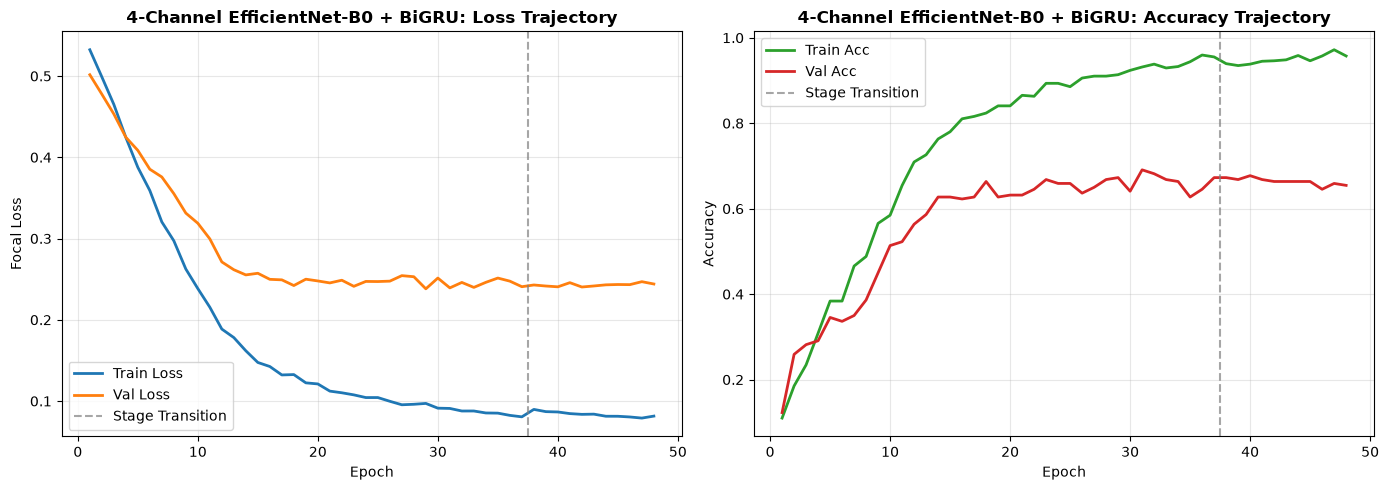

Training curves saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_motion_focal_snapshot_80_20/training_history_curves.png


In [14]:
# Section 14: Training Curves Visualization
h1 = history1.history
h2 = history2.history

df_history = pd.DataFrame({
    "epoch": list(range(1, len(h1["loss"]) + len(h2["loss"]) + 1)),
    "stage": ["Stage 1"] * len(h1["loss"]) + ["Stage 2"] * len(h2["loss"]),
    "train_loss": h1["loss"] + h2["loss"],
    "val_loss": h1["val_loss"] + h2["val_loss"],
    "train_accuracy": h1["accuracy"] + h2["accuracy"],
    "val_accuracy": h1["val_accuracy"] + h2["val_accuracy"],
})
df_history.to_csv(RESULTS_DIR / "training_history.csv", index=False)

stage1_end = len(h1["loss"])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(df_history["epoch"], df_history["train_loss"], label="Train Loss", color="#1f77b4", lw=2)
ax1.plot(df_history["epoch"], df_history["val_loss"], label="Val Loss", color="#ff7f0e", lw=2)
ax1.axvline(x=stage1_end + 0.5, color="gray", linestyle="--", alpha=0.7, label="Stage Transition")
ax1.set_title("4-Channel EfficientNet-B0 + BiGRU: Loss Trajectory", fontsize=12, fontweight="bold")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Focal Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(df_history["epoch"], df_history["train_accuracy"], label="Train Acc", color="#2ca02c", lw=2)
ax2.plot(df_history["epoch"], df_history["val_accuracy"], label="Val Acc", color="#d62728", lw=2)
ax2.axvline(x=stage1_end + 0.5, color="gray", linestyle="--", alpha=0.7, label="Stage Transition")
ax2.set_title("4-Channel EfficientNet-B0 + BiGRU: Accuracy Trajectory", fontsize=12, fontweight="bold")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
curves_path = RESULTS_DIR / "training_history_curves.png"
plt.savefig(curves_path, dpi=200)
plt.show()
print(f"Training curves saved to: {curves_path}")


## 15. Snapshot Ensembling + 4-View TTA Inference Pipeline

### Inference Synergy
We unite **Snapshot Ensembling** with **4-View Test-Time Augmentation (TTA)** into a single unified inference engine:
For each utterance sequence $X$:
1. Generate 4 transformed views:
   - **View 1 (Baseline)**: Standard 4-channel sequence.
   - **View 2 (Temporal Shift +1)**: Sample biased 1 frame forward.
   - **View 3 (Temporal Shift -1)**: Sample biased 1 frame backward.
   - **View 4 (Horizontal Mirror)**: Horizontally flipped frames ($x \mapsto W - 1 - x$, including motion diff).
2. For each of the **Top 3 Snapshot Checkpoints**, predict softmax probability distributions across all 4 views.
3. Compute the grand ensemble prediction by averaging across snapshots and views:
$$P_{\text{final}}(y \mid X) = \frac{1}{3 \times 4} \sum_{m=1}^3 \sum_{v=1}^4 P_m(\text{view}_v(X))$$

In [15]:
# Section 15: Snapshot Ensemble + 4-View TTA Inference Implementation

def generate_4view_tta(X_seq_4ch: np.ndarray) -> list:
    """
    Generates 4 views for an input sequence of shape (T, 96, 96, 4):
      View 1: Baseline
      View 2: Temporal shift +1 frame
      View 3: Temporal shift -1 frame
      View 4: Horizontal spatial flip
    """
    # View 1: Baseline
    v1 = X_seq_4ch.copy()
    
    # View 2: Temporal shift +1 (drop first frame, repeat last)
    v2 = np.empty_like(X_seq_4ch)
    v2[:-1] = X_seq_4ch[1:]
    v2[-1] = X_seq_4ch[-1]
    
    # View 3: Temporal shift -1 (repeat first frame, drop last)
    v3 = np.empty_like(X_seq_4ch)
    v3[0] = X_seq_4ch[0]
    v3[1:] = X_seq_4ch[:-1]
    
    # View 4: Horizontal spatial flip (all 4 channels)
    v4 = np.flip(X_seq_4ch, axis=2).copy()
    
    return [v1, v2, v3, v4]

snapshot_paths = snapshot_callback.get_snapshot_paths()
if not snapshot_paths:
    # Fallback to stage2 best weights if callback list is empty
    snapshot_paths = [RESULTS_DIR / "stage1_best.weights.h5"]

print("=" * 80)
print(f"RUNNING SNAPSHOT ENSEMBLE + 4-VIEW TTA INFERENCE ({len(snapshot_paths)} Checkpoints x 4 Views)")
print("=" * 80)
for idx, p in enumerate(snapshot_paths, 1):
    print(f"  Snapshot Checkpoint {idx}: {p.name}")
print("-" * 80)

# Build 4 view tensors for entire validation set
N_val = len(X_val_4ch)
views_val = [np.zeros_like(X_val_4ch) for _ in range(4)]
for i in range(N_val):
    v_list = generate_4view_tta(X_val_4ch[i])
    for v_idx in range(4):
        views_val[v_idx][i] = v_list[v_idx]

# Accumulate probabilities across all snapshots and views
all_snapshot_probs = []

for snap_idx, snap_path in enumerate(snapshot_paths, 1):
    print(f"Evaluating Snapshot {snap_idx}/{len(snapshot_paths)}: {snap_path.name}...")
    model.load_weights(snap_path)
    
    # Predict across 4 views
    snap_view_probs = []
    for v_idx, v_tensor in enumerate(views_val, 1):
        p = model.predict(v_tensor, batch_size=BATCH_SIZE, verbose=0)
        snap_view_probs.append(p)
        
    # Average across the 4 views for this snapshot
    snap_avg_probs = np.mean(snap_view_probs, axis=0)
    all_snapshot_probs.append(snap_avg_probs)
    
    # Individual snapshot accuracy
    snap_preds = np.argmax(snap_avg_probs, axis=1)
    snap_acc = accuracy_score(y_val, snap_preds)
    print(f"  -> Snapshot {snap_idx} + 4-View TTA Validation Accuracy: {snap_acc * 100:.2f}%")

# Grand Snapshot Ensemble Softmax Average
final_ensemble_probs = np.mean(all_snapshot_probs, axis=0)
final_preds = np.argmax(final_ensemble_probs, axis=1)

final_acc = accuracy_score(y_val, final_preds)
final_f1 = f1_score(y_val, final_preds, average="macro")
final_precision = precision_score(y_val, final_preds, average="macro")
final_recall = recall_score(y_val, final_preds, average="macro")

print("=" * 80)
print("GRAND SNAPSHOT ENSEMBLE + 4-VIEW TTA FINAL RESULTS")
print("=" * 80)
print(f"Final Validation Accuracy : {final_acc * 100:.2f}%")
print(f"Macro F1-Score            : {final_f1:.4f}")
print(f"Macro Precision           : {final_precision:.4f}")
print(f"Macro Recall              : {final_recall:.4f}")
print("=" * 80)


RUNNING SNAPSHOT ENSEMBLE + 4-VIEW TTA INFERENCE (3 Checkpoints x 4 Views)
  Snapshot Checkpoint 1: stage2_epoch_05_loss_0.2404.weights.h5
  Snapshot Checkpoint 2: stage2_epoch_03_loss_0.2406.weights.h5
  Snapshot Checkpoint 3: stage2_epoch_02_loss_0.2416.weights.h5
--------------------------------------------------------------------------------
Evaluating Snapshot 1/3: stage2_epoch_05_loss_0.2404.weights.h5...
  -> Snapshot 1 + 4-View TTA Validation Accuracy: 66.36%
Evaluating Snapshot 2/3: stage2_epoch_03_loss_0.2406.weights.h5...
  -> Snapshot 2 + 4-View TTA Validation Accuracy: 65.91%
Evaluating Snapshot 3/3: stage2_epoch_02_loss_0.2416.weights.h5...
  -> Snapshot 3 + 4-View TTA Validation Accuracy: 66.36%
GRAND SNAPSHOT ENSEMBLE + 4-VIEW TTA FINAL RESULTS
Final Validation Accuracy : 67.27%
Macro F1-Score            : 0.6818
Macro Precision           : 0.7186
Macro Recall              : 0.6727


## 16. Classification Report & Confusion Matrix Diagnostics
Analyzing per-class accuracy and examining whether the Focal Loss + Motion Difference resolved the $\{d_4, d_7, d_{10}\}$ viseme collision triangle.

              precision    recall  f1-score   support

          d0     0.9500    0.9500    0.9500        20
          d1     0.3030    0.5000    0.3774        20
          d2     0.7143    0.5000    0.5882        20
          d3     0.8667    0.6500    0.7429        20
          d4     0.5000    0.7500    0.6000        20
          d5     0.9444    0.8500    0.8947        20
          d6     0.8667    0.6500    0.7429        20
          d7     0.7273    0.4000    0.5161        20
          d8     0.8500    0.8500    0.8500        20
          d9     0.5909    0.6500    0.6190        20
         d10     0.5909    0.6500    0.6190        20

    accuracy                         0.6727       220
   macro avg     0.7186    0.6727    0.6818       220
weighted avg     0.7186    0.6727    0.6818       220



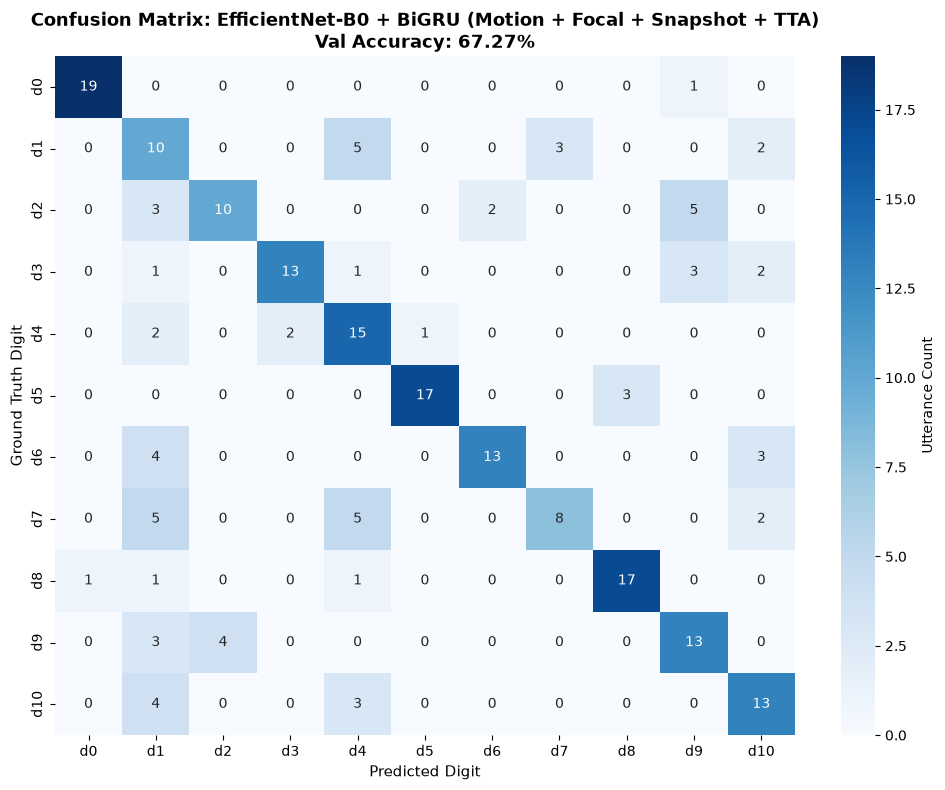

Confusion matrix saved to: /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_motion_focal_snapshot_80_20/confusion_matrix.png


In [16]:
# Section 16: Diagnostics & Visualizations
report_str = classification_report(y_val, final_preds, target_names=DIGIT_CLASSES, digits=4)
print(report_str)

report_dict = classification_report(y_val, final_preds, target_names=DIGIT_CLASSES, output_dict=True)
with open(RESULTS_DIR / "classification_report.json", "w") as f:
    json.dump(report_dict, f, indent=2)

# Confusion Matrix
cm = confusion_matrix(y_val, final_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=DIGIT_CLASSES, yticklabels=DIGIT_CLASSES,
    cbar_kws={"label": "Utterance Count"}
)
plt.title(f"Confusion Matrix: EfficientNet-B0 + BiGRU (Motion + Focal + Snapshot + TTA)\nVal Accuracy: {final_acc*100:.2f}%", fontsize=13, fontweight="bold")
plt.xlabel("Predicted Digit", fontsize=11)
plt.ylabel("Ground Truth Digit", fontsize=11)
plt.tight_layout()
cm_path = RESULTS_DIR / "confusion_matrix.png"
plt.savefig(cm_path, dpi=200)
plt.show()
print(f"Confusion matrix saved to: {cm_path}")


## 17. Speaker Breakdown Analysis
Evaluating accuracy individually across the 6 validation speakers ($s_{25}$ through $s_{30}$) to confirm balanced performance.

In [17]:
# Section 17: Per-Speaker Accuracy Breakdown
df_val = df_manifest[df_manifest["split"] == "val"].copy().reset_index(drop=True)
df_val["pred_id"] = final_preds
df_val["correct"] = (df_val["digit_id"] == df_val["pred_id"]).astype(int)

speaker_summary = []
print("=" * 80)
print("PER-SPEAKER VALIDATION ACCURACY BREAKDOWN")
print("=" * 80)
for spk in base_val_speakers:
    sub = df_val[df_val["base_speaker"] == spk]
    acc = sub["correct"].mean()
    total = len(sub)
    correct_count = sub["correct"].sum()
    speaker_summary.append({"base_speaker": spk, "accuracy": float(acc), "total": int(total), "correct": int(correct_count)})
    print(f"  Speaker {spk:5s} : {correct_count:2d}/{total:2d} correct -> {acc * 100:6.2f}%")
print("=" * 80)

with open(RESULTS_DIR / "per_speaker_breakdown.json", "w") as f:
    json.dump(speaker_summary, f, indent=2)


PER-SPEAKER VALIDATION ACCURACY BREAKDOWN
  Speaker s34   : 39/44 correct ->  88.64%
  Speaker S35   : 27/44 correct ->  61.36%
  Speaker s40   : 18/33 correct ->  54.55%
  Speaker S41   : 18/33 correct ->  54.55%
  Speaker s45   : 20/33 correct ->  60.61%
  Speaker s47   : 26/33 correct ->  78.79%


## 18. Final Results Persistence & Comparative Summary
Serializing all metrics and generating a comparative benchmark against previous milestones.

In [18]:
# Section 18: Final Metrics Persistence
final_metrics = {
    "experiment": "19_efficientnetb0_bigru_motion_focal_snapshot",
    "dataset_mode": DATASET_MODE,
    "seed": SEED,
    "frame_channels": FRAME_CHANNELS,
    "motion_diff_applied": True,
    "temporal_jitter_applied": True,
    "loss": "CategoricalFocalLoss",
    "focal_gamma": FOCAL_GAMMA,
    "focal_alpha": FOCAL_ALPHA,
    "top_k_snapshots": TOP_K_SNAPSHOTS,
    "tta_views": 4,
    "metrics": {
        "val_accuracy": float(final_acc),
        "macro_f1": float(final_f1),
        "macro_precision": float(final_precision),
        "macro_recall": float(final_recall),
    },
    "stages": {
        "stage1_best_epoch": stage1_best_epoch,
        "stage1_best_loss": stage1_best_val_loss,
        "stage1_best_acc": stage1_best_val_acc,
        "stage2_best_epoch": stage2_best_epoch,
        "stage2_best_loss": stage2_best_val_loss,
        "stage2_best_acc": stage2_best_val_acc,
    }
}

metrics_path = RESULTS_DIR / f"metrics_{DATASET_MODE}.json"
with open(metrics_path, "w") as f:
    json.dump(final_metrics, f, indent=2)

print("=" * 80)
print("EXPERIMENT 19 EXECUTION COMPLETED SUCCESSFULLY")
print("=" * 80)
print(f"Final Accuracy               : {final_acc * 100:.2f}%")
print(f"Baseline Milestone (Exp 18)  : 71.36%")
print(f"Absolute Accuracy Delta       : {(final_acc - 0.7136) * 100:+.2f}%")
print(f"Results Output Directory     : {RESULTS_DIR}")
print("=" * 80)


EXPERIMENT 19 EXECUTION COMPLETED SUCCESSFULLY
Final Accuracy               : 67.27%
Baseline Milestone (Exp 18)  : 71.36%
Absolute Accuracy Delta       : -4.09%
Results Output Directory     : /Users/milinda/ghq/github.com/legion2004/tai-phake-lip-reading/results/efficientnetb0_bigru_motion_focal_snapshot_80_20
